# Nodal Uncertainty and Risk — Primitives, OPF Propagation, and the Risk-Loaded Premium

> **Work in progress** — an illustrative teaching notebook under active development, not an authoritative reference.

Every later notebook that prices risk needs a distribution of **nodal prices and congestion**. This
includes the seams notebooks and the transmission-hedge auctions. A distribution written down
directly, as a mean and spread for each bus's LMP, is not used here. A set of nodal prices invented
that way need not be one any dispatch produces, and it will not be revenue-adequate.

Instead this notebook builds the **primitives + OPF-propagation** architecture the shared `risk.py`
library uses:

1. The uncertainty sits in the **drivers**: a per-bus **load** distribution and a per-generator
   **cost** distribution. These are the things that are random tomorrow.
2. **Scenarios are drawn** over those drivers (Monte-Carlo, or Gauss-Hermite quadrature for a small slice).
3. **The DC-OPF is cleared** for each draw, so the nodal prices and congestion are induced by the
   clearing. The result is physically consistent with the network and revenue-adequate by construction.
4. The **certainty-equivalent** and the **risk-loaded premium** a risk-averse party will pay to hedge
   the induced congestion are read off.

$$\underbrace{\text{load, cost dists}}_{\text{primitives}} \;\to\;
  \underbrace{\text{scenarios}}_{\text{MC / GH}} \;\to\;
  \underbrace{\text{clear DC-OPF each}}_{\text{propagation}} \;\to\;
  \underbrace{\text{induced congestion dist}}_{\lambda_k-\lambda_s} \;\to\;
  \underbrace{\text{CE, risk-loaded premium}}_{\text{risk preference}}$$

Each step is one call into `risk.py`.

## 0. Setup

In [1]:
#@title ▶ Run me first ▶ Colab setup (installs packages, fetches the helper modules)
import sys, subprocess

def _sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)

if "google.colab" in sys.modules:
    _sh("pip install -q pypsa pandapower")
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main"
    for _f in ("ieee9_network.py", "seams_engine.py", "wscc9_model.py", "footprints.py", "risk.py"):
        _sh(f"wget -q {_base}/{_f} -O {_f}")
    print("Colab setup complete.")
else:
    # Local run inside western-illustrative-models: the shared modules live in
    # this half's lib/ folder. Walk up from the working directory to find it
    # and put it on sys.path, so the notebook runs from notebooks/ or the root.
    import pathlib
    _r = pathlib.Path.cwd()
    while not (_r / "lib" / "seams_engine.py").exists() and _r != _r.parent:
        _r = _r.parent
    _lib = _r / "lib"
    if _lib.exists():
        if str(_lib) not in sys.path:
            sys.path.insert(0, str(_lib))
        print(f"Local run: modules from {_lib}")
    else:
        print("Local run: using the modules already in this folder.")

Local run: using the modules already in this folder.


In [2]:
import sys, os, importlib
import warnings; warnings.filterwarnings('ignore')
import logging; logging.getLogger('pypsa').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, norm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sys.path.insert(0, os.path.abspath('.'))
import wscc9_model, seams_engine, risk
for _m in (wscc9_model, seams_engine, risk):
    importlib.reload(_m)
import wscc9_model as wm, risk as rk
from wscc9_model import build_network, BUS_COLORS
from seams_engine import compute_ptdf

pd.set_option('display.width', 160)
rng = np.random.default_rng(0)                     # one seeded generator -- reproducible draws
print('ready')

ready

## 1. The primitives — distributions on the drivers, not the prices

**Nomenclature.** The table gives the risk track's vocabulary. The `Code`
column is where each object lives in `risk.py`.

| Symbol | Code | Definition |
|---|---|---|
| load / cost drivers | `risk.load_dists` / `risk.cost_dists` (`risk.Normal`) | per-bus load and per-generator cost distributions — the primitives |
| scenario set | `risk.monte_carlo` / `risk.gauss_hermite` (`risk.Scenarios`) | joint draws over the drivers (equal-weight MC, or GH quadrature nodes and weights) |
| $\lambda_n$ | `risk.induced_lmps` | the nodal LMP at bus $n$ induced by clearing the OPF on one draw |
| $c$ | `risk.path_congestion` | the random congestion cost a point-to-point right spans, $\lambda_k-\lambda_s$ |
| $\mathbb E[X]$, $\mathrm{Var}[X]$ | `risk.emean` / `risk.evar` | mean and variance over the drawn scenarios |
| $\gamma$ | `risk.GAMMA_LADDER` | the risk-aversion coefficient (mean-variance / Arrow–Pratt) |
| $\mathrm{CE}_\gamma$ | `risk.certainty_equivalent` | the certainty equivalent of a random payoff under risk aversion $\gamma$ |
| $\pi$ | `risk.risk_loaded_premium` | the risk-loaded hedge value of a right paying the random cost $c$ |


The random things tomorrow are **load** at each bus and the **marginal cost** of each generator. The
nodal prices are whatever the dispatch makes of them. Therefore `risk.py` keeps one canonical set of
drivers, edited once in the library:

- a **per-bus load** distribution: mean = the base load, spread = `DEFAULT_LOAD_SD` (≈15% here);
- a **per-generator cost** distribution: mean = the fleet cost, spread = `DEFAULT_COST_SD` (the dear
  bus-1 unit is the most volatile, the cheap bus-3 unit the most stable).

Each driver is a `Normal(mean, sd)`. These values are illustrative and meant to be tuned. The architecture carries the content, not the
exact numbers.

In [3]:
ld, ct = rk.load_dists(), rk.cost_dists()
print('Per-bus LOAD drivers  (mean = DEFAULT_LOADS, sd = DEFAULT_LOAD_SD):')
display(pd.DataFrame({b: {'mean (MW)': d.mean, 'sd (MW)': d.sd} for (_, b), d in ld.items()}).T)
print('Per-generator COST drivers  (mean = fleet cost, sd = DEFAULT_COST_SD):')
display(pd.DataFrame({g: {'mean ($/MWh)': d.mean, 'sd ($/MWh)': d.sd} for (_, g), d in ct.items()}).T)
print('canonical risk-aversion ladder  gamma =', rk.GAMMA_LADDER)

Per-bus LOAD drivers  (mean = DEFAULT_LOADS, sd = DEFAULT_LOAD_SD):

,mean (MW),sd (MW)
5,90.0,13.0
7,100.0,15.0
9,125.0,19.0


Per-generator COST drivers  (mean = fleet cost, sd = DEFAULT_COST_SD):

,mean ($/MWh),sd ($/MWh)
gen_slack_0,50.0,12.0
gen_0,35.0,7.0
gen_1,20.0,3.0


canonical risk-aversion ladder  gamma =

(0.0, 0.005, 0.02)

## 2. Scenarios — drawing from the drivers

A **scenario** is one joint draw of every driver. `monte_carlo` takes independent normal draws at equal
weights. `gauss_hermite` (Section 5) places deterministic quadrature nodes instead. This section makes
the whole per-node set uncertain: all three loads and all three costs. A few hundred scenarios are drawn.

In [4]:
# -- EDIT the driver distributions here (mean and sd, by node) ----------------------------
# Defaults live in risk.py; override any node's mean and/or sd. Loads are keyed by BUS, costs by
# GENERATOR id (gen_slack_0 -> bus 1, gen_0 -> bus 2, gen_1 -> bus 3). Uncomment to use:
#
# dists = {
#     **rk.load_dists(loads={'7': 120.0, '9': 130.0},                 # bus 7, 9 load MEANS (MW)
#                     sd   ={'7': 30.0}),                             # bus 7 load SD (MW)
#     **rk.cost_dists(cost ={'gen_slack_0': 55.0},                    # bus-1 gen cost MEAN ($/MWh)
#                     sd   ={'gen_slack_0': 15.0, 'gen_1': 5.0}),     # bus-1, bus-3 gen cost SDs ($/MWh)
# }
dists = {**rk.load_dists(), **rk.cost_dists()}          # the drivers we let vary (defaults from risk.py)
scen = rk.monte_carlo(dists, n=500, rng=rng)
print(f'{scen.S} Monte-Carlo scenarios over {len(scen.keys)} drivers; first 5 draws:')
display(pd.DataFrame({f'{k[0]}:{k[1]}': scen.draws[k][:5] for k in scen.keys}).round(1))

500 Monte-Carlo scenarios over 6 drivers; first 5 draws:

,load:5,load:7,load:9,cost:gen_slack_0,cost:gen_0,cost:gen_1
0,91.6,119.4,147.5,64.4,37.9,17.4
1,88.3,106.8,130.8,42.9,31.5,13.4
2,98.3,74.6,128.6,35.5,29.0,17.3
3,91.4,89.1,130.1,46.5,23.8,18.5
4,83.0,118.5,99.0,40.2,23.2,24.4


## 3. Propagation — clear the OPF, induce the nodal distributions

The load-bearing step is the propagation. The cheap corridor $\texttt{line\_4}$ (6–7) is bound at 40 MW
and, for **every** scenario, the DC-OPF is cleared with that scenario's drawn loads and costs. One solve per scenario gives the
induced **nodal price** at every bus. Each node's LMP is itself a *distribution*, produced by the
network from the input uncertainty rather than assumed.

In [5]:
ptC = compute_ptdf(build_network({'line_4': 40.0}), slack_bus='1')
lmps, w, buses = rk.induced_lmps(ptC, scen)        # one DC-OPF solve per scenario -> all 9 nodal LMPs
print(f'cleared {scen.S} scenarios; induced LMP matrix {lmps.shape} (scenarios x buses {buses})')

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


cleared 500 scenarios; induced LMP matrix (500, 9) (scenarios x buses ['1', '2', '3', '4', '5', '6', '7', '8', '9'])

### The input distributions, node by node

The **inputs** that vary are shown first: the drivers of Section 1, one panel per bus, drawn like the
congestion plot below. The light **histogram** is the actual 500 scenario draws, the curve is the
**specified Normal**, and the vertical lines are the sample **mean** (dashed) and **median** (solid).
Because a Normal is symmetric the mean and median sit essentially on top of each other. A generator bus
carries a *cost* driver and a load bus a *load* driver. The passive buses (4, 6, 8) have no input and
stay fixed. These nine panels are the marginals of the joint input distribution the scenarios sample.

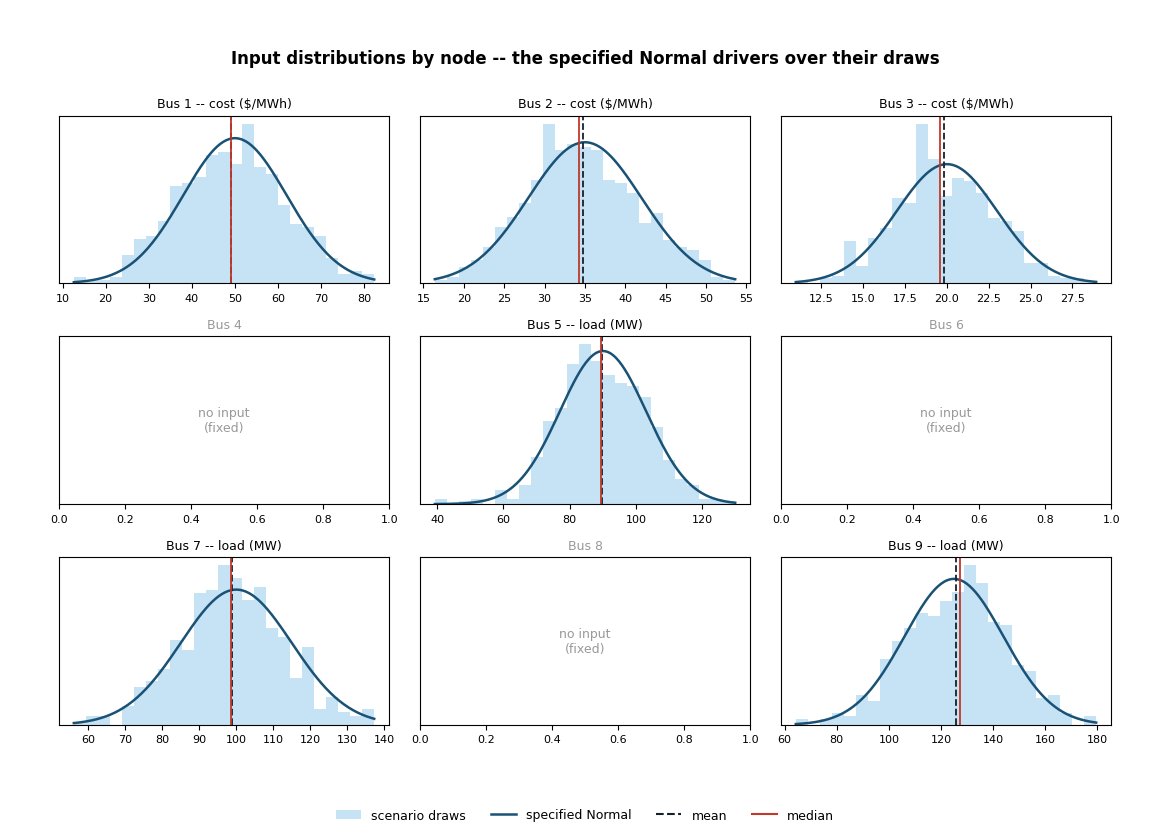

In [6]:
ld, ct = rk.load_dists(), rk.cost_dists()
gen_bus = {g: s['bus'] for g, s in wm.DEFAULT_GEN_FLEET.items()}   # gen id -> its bus
inp = {}                                                          # bus -> (label, samples, Normal)
for k in scen.keys:
    if k[0] == 'cost': inp[gen_bus[k[1]]] = ('cost ($/MWh)', scen.draws[k], ct[k])
    else:              inp[k[1]]          = ('load (MW)',    scen.draws[k], ld[k])

fig, axes = plt.subplots(3, 3, figsize=(11.0, 7.4))
for ax, b in zip(axes.ravel(), [str(i) for i in range(1, 10)]):
    if b in inp:
        lab, samp, d = inp[b]
        ax.hist(samp, bins=25, density=True, color='#AED6F1', alpha=0.7)
        xs = np.linspace(samp.min(), samp.max(), 200)
        ax.plot(xs, norm.pdf(xs, d.mean, d.sd), color='#1A5276', lw=1.8)        # the specified Normal
        ax.axvline(rk.emean(samp, scen.weight),         color='#17202A', ls='--', lw=1.3)  # mean
        ax.axvline(rk.equantile(samp, scen.weight, .5), color='#C0392B', ls='-', lw=1.3)   # median
        ax.set_title(f'Bus {b} -- {lab}', fontsize=9)
    else:
        ax.text(0.5, 0.5, 'no input\n(fixed)', ha='center', va='center', color='#999',
                fontsize=9, transform=ax.transAxes); ax.set_title(f'Bus {b}', fontsize=9, color='#999')
    ax.set_yticks([]); ax.tick_params(labelsize=8)
_leg = [Patch(fc='#AED6F1', alpha=0.7, label='scenario draws'),
        Line2D([0], [0], color='#1A5276', lw=1.8, label='specified Normal'),
        Line2D([0], [0], color='#17202A', ls='--', label='mean'),
        Line2D([0], [0], color='#C0392B', label='median')]
fig.legend(handles=_leg, ncol=4, loc='lower center', fontsize=9, frameon=False)
fig.suptitle('Input distributions by node -- the specified Normal drivers over their draws',
             fontweight='bold', y=1.0)
plt.tight_layout(rect=[0, 0.04, 1, 1]); plt.show()

### The output distributions, node by node

Now the **outputs**: each bus's LMP, induced by clearing the OPF under the same draws, with the same
histogram + density + mean/median overlay (the density here is the empirical KDE, not a Normal). The passive buses (4, 6, 8) have fixed inputs yet variable prices. The network makes them. The
induced densities are not Normal. Where congestion clips a price or the marginal unit switches, the
distribution skews, so the mean and median separate. That skew is the fingerprint of the nonlinear
dispatch.

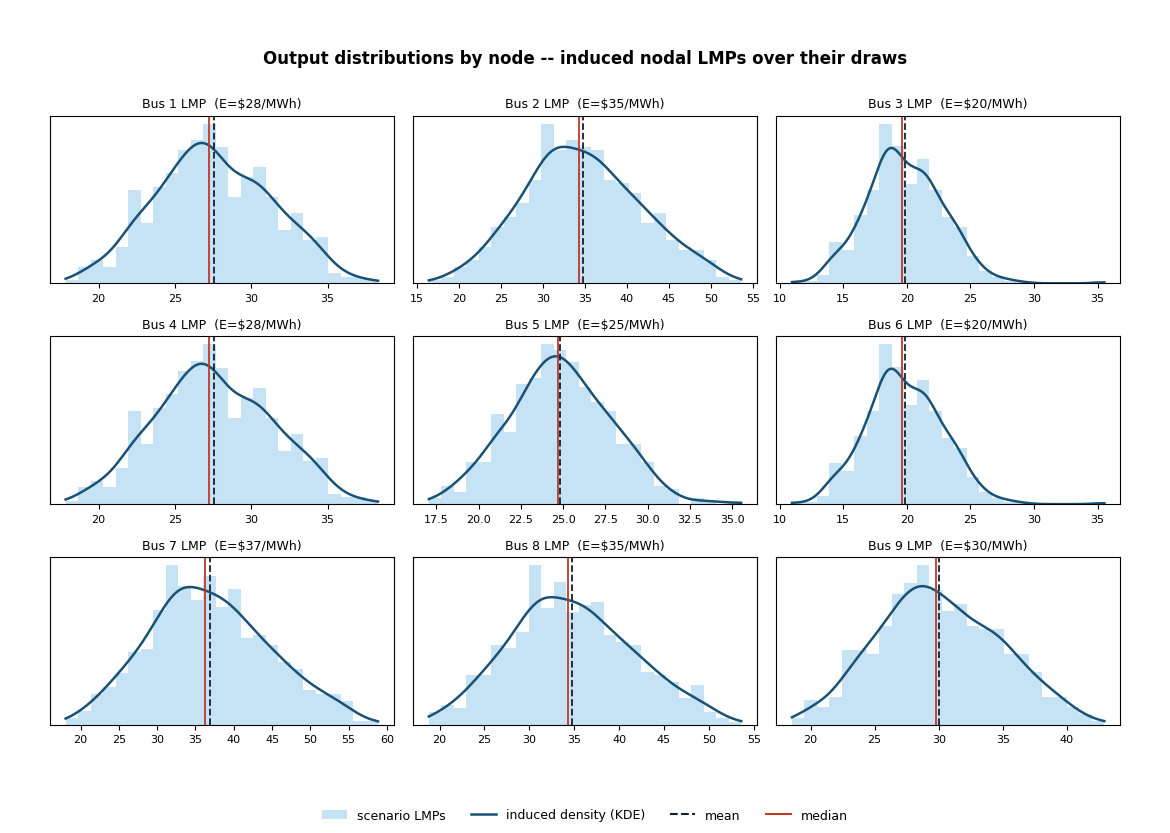

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(11.0, 7.4))
for ax, b in zip(axes.ravel(), [str(i) for i in range(1, 10)]):
    samp = lmps[:, buses.index(b)]
    ax.hist(samp, bins=25, density=True, color='#AED6F1', alpha=0.7)
    if samp.std() > 1e-6:
        xs = np.linspace(samp.min(), samp.max(), 200)
        ax.plot(xs, gaussian_kde(samp)(xs), color='#1A5276', lw=1.8)            # induced (empirical) density
    ax.axvline(rk.emean(samp, w),         color='#17202A', ls='--', lw=1.3)     # mean
    ax.axvline(rk.equantile(samp, w, .5), color='#C0392B', ls='-', lw=1.3)      # median
    ax.set_title(f'Bus {b} LMP  (E=${rk.emean(samp, w):.0f}/MWh)', fontsize=9)
    ax.set_yticks([]); ax.tick_params(labelsize=8)
_leg = [Patch(fc='#AED6F1', alpha=0.7, label='scenario LMPs'),
        Line2D([0], [0], color='#1A5276', lw=1.8, label='induced density (KDE)'),
        Line2D([0], [0], color='#17202A', ls='--', label='mean'),
        Line2D([0], [0], color='#C0392B', label='median')]
fig.legend(handles=_leg, ncol=4, loc='lower center', fontsize=9, frameon=False)
fig.suptitle('Output distributions by node -- induced nodal LMPs over their draws',
             fontweight='bold', y=1.0)
plt.tight_layout(rect=[0, 0.04, 1, 1]); plt.show()

### A point-to-point right spans two nodes (a first look ahead)

One object is built from those marginals: a preview of the transmission-hedge notebooks. The congestion a
point-to-point right on $3\to 7$ hedges is the price separation $\lambda_7-\lambda_3$: a **difference**
of two of the columns above. Collected across scenarios it is again a distribution. Sometimes the
corridor barely binds and sometimes it binds hard. It is the one the risk-loaded premium of Section 4 prices.

induced congestion on 3->7 (lambda_7 - lambda_3):

  E = $17.04/MW    sd = $8.63/MW    5-95% = [$3.2, $32.2]/MW

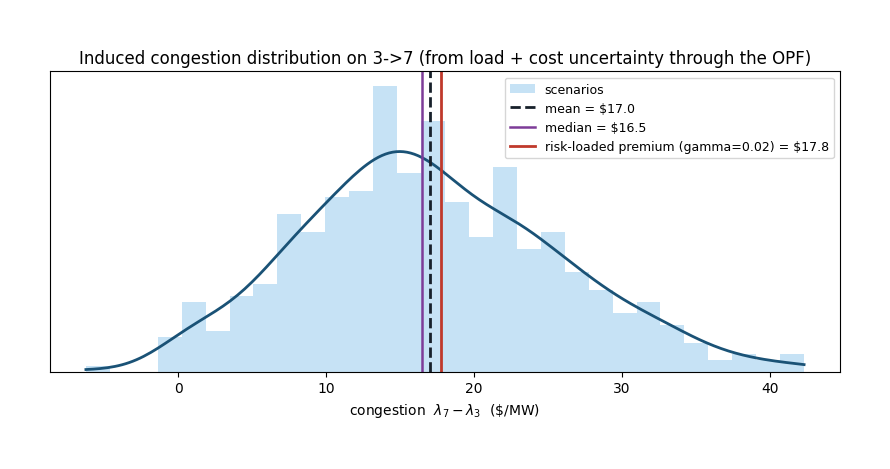

In [8]:
b3, b7 = buses.index('3'), buses.index('7')
cong = lmps[:, b7] - lmps[:, b3]                   # lambda_7 - lambda_3, straight from the induced LMPs
E, sd = rk.emean(cong, w), rk.evar(cong, w) ** 0.5
print('induced congestion on 3->7 (lambda_7 - lambda_3):')
print(f'  E = ${E:.2f}/MW    sd = ${sd:.2f}/MW    '
      f'5-95% = [${rk.equantile(cong, w, .05):.1f}, ${rk.equantile(cong, w, .95):.1f}]/MW')

fig, ax = plt.subplots(figsize=(8.2, 4.0))
ax.hist(cong, bins=30, weights=w, density=True, color='#AED6F1', alpha=0.7, label='scenarios')
xs = np.linspace(cong.min(), cong.max(), 200)
ax.plot(xs, gaussian_kde(cong)(xs), color='#1A5276', lw=2)
ax.axvline(E, color='#17202A', ls='--', lw=2, label=f'mean = ${E:.1f}')
_med = rk.equantile(cong, w, .5)
ax.axvline(_med, color='#7D3C98', lw=1.8, label=f'median = ${_med:.1f}')
prem = rk.risk_loaded_premium(cong, w, 0.02)
ax.axvline(prem, color='#C0392B', lw=2, label=f'risk-loaded premium (gamma=0.02) = ${prem:.1f}')
ax.set_xlabel('congestion  $\\lambda_7-\\lambda_3$  (\\$/MW)'); ax.set_yticks([])
ax.set_title('Induced congestion distribution on 3->7 (from load + cost uncertainty through the OPF)')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

## 4. Risk preference — the certainty equivalent and the risk-loaded premium

A risk-averse party summarizes a random payoff by its **certainty equivalent**, the mean discounted by
the variance (the repo's mean-variance convention),

$$\mathrm{CE}_\gamma \;=\; \mathbb{E}[X] - \tfrac{\gamma}{2}\,\mathrm{Var}[X], \tag{1}$$

*In words.* The certainty equivalent $\mathrm{CE}_\gamma$ of a random payoff $X$ is its mean $\mathbb E[X]$ minus half the risk-aversion coefficient $\gamma$ times its variance $\mathrm{Var}[X]$. At $\gamma=0$ the penalty vanishes and the certainty equivalent is just the mean.

with $\gamma$ the risk-aversion coefficient. A transmission customer facing the random congestion cost
$c=\lambda_k-\lambda_s$ will pay, for a right that pays $c$, up to its **risk-loaded hedge value**

$$\pi \;=\; \mathbb{E}[c] + \tfrac{\gamma}{2}\,\mathrm{Var}[c]. \tag{2}$$

*In words.* The risk-loaded hedge value $\pi$ of a right paying the random congestion cost $c$ is the expected congestion $\mathbb E[c]$ plus half the risk-aversion coefficient $\gamma$ times its variance $\mathrm{Var}[c]$ — eq. (1)'s penalty with its sign flipped, because $c$ is a cost rather than a payoff.

At $\gamma=0$ that is the **expected** congestion. Risk aversion loads it *above* the mean by the
variance. That gap is why a hedge can clear on **hedge value**, not on any single realized congestion.
That value is the premium the transmission-rights auctions take as each customer's bid.

In [9]:
V = rk.evar(cong, w)
tbl = pd.DataFrame([{
    'gamma': g,
    'E[c] ($/MW)': round(E, 2),
    'Var[c]': round(V, 1),
    'CE of the hedge ($/MW)': round(rk.certainty_equivalent(cong, w, g), 2),
    'risk-loaded premium pi ($/MW)': round(rk.risk_loaded_premium(cong, w, g), 2),
    'load over E[c] ($/MW)': round(rk.risk_loaded_premium(cong, w, g) - E, 2),
} for g in rk.GAMMA_LADDER]).set_index('gamma')
display(tbl)
print('At gamma=0 the premium is the EXPECTED congestion; higher gamma loads it above the mean by the')
print('variance -- the customer pays extra for certainty, so its bid exceeds any single realized spread.')

,E[c] ($/MW),Var[c],CE of the hedge ($/MW),risk-loaded premium pi ($/MW),load over E[c] ($/MW)
gamma,,,,,
0.000,17.04,74.5,17.04,17.04,0.00
0.005,17.04,74.5,16.85,17.22,0.19
0.020,17.04,74.5,16.29,17.78,0.74


At gamma=0 the premium is the EXPECTED congestion; higher gamma loads it above the mean by the

variance -- the customer pays extra for certainty, so its bid exceeds any single realized spread.

## 5. Gauss-Hermite — a deterministic slice

Monte-Carlo is the workhorse for the full per-node set. When only one or two drivers matter, **Gauss-
Hermite quadrature** integrates them exactly with a handful of *deterministic* nodes (no RNG). It is the
device the seams notebooks use. This section varies just the bus-1 cost and the bus-7 load. The
corridor stays bound, so $3\to 7$'s congestion barely moves and the premium sits right at the mean.

In [10]:
slice2 = {('cost', 'gen_slack_0'): rk.Normal(50.0, 12.0), ('load', '7'): rk.Normal(100.0, 15.0)}
v2, w2 = rk.propagate(ptC, rk.gauss_hermite(slice2, nodes=7), rk.path_congestion('3', '7'))
print(f'Gauss-Hermite over 2 drivers ({len(w2)} deterministic nodes):')
print(f'  E[congestion 3->7] = ${rk.emean(v2, w2):.2f}/MW    sd = ${rk.evar(v2, w2) ** 0.5:.2f}/MW')
print(f'  risk-loaded premium (gamma=0.02) = ${rk.risk_loaded_premium(v2, w2, 0.02):.2f}/MW')
print('(the full-node Monte-Carlo of Section 3 carries far more variance -- varying ALL loads and costs')
print(' sometimes unbinds the corridor, which this 2-driver slice cannot.)')

Gauss-Hermite over 2 drivers (49 deterministic nodes):

  E[congestion 3->7] = $17.13/MW    sd = $0.06/MW

  risk-loaded premium (gamma=0.02) = $17.13/MW

(the full-node Monte-Carlo of Section 3 carries far more variance -- varying ALL loads and costs

 sometimes unbinds the corridor, which this 2-driver slice cannot.)

## 6. Sandbox

Change the path, the drivers that vary, the number of scenarios, and the risk aversion, then re-run.
Widening a load's or a cost's spread fattens the induced congestion distribution and pulls the
risk-loaded premium away from the expected congestion.

In [11]:
# -- EDIT --
SB_PATH   = ('3', '7')          # the point-to-point path to price (source, sink)
SB_LINE4  = 40.0                # line 6-7 rating (MW)
SB_N      = 500                 # Monte-Carlo scenarios
SB_GAMMA  = 0.02                # risk aversion
SB_DISTS  = {**rk.load_dists(), **rk.cost_dists()}   # e.g. {**rk.load_dists(sd={'7': 30.0})}
# ----------
_pt = compute_ptdf(build_network({'line_4': SB_LINE4}), slack_bus='1')
_scen = rk.monte_carlo(SB_DISTS, n=SB_N, rng=np.random.default_rng(1))
_c, _w = rk.propagate(_pt, _scen, rk.path_congestion(*SB_PATH))
print(f'path {SB_PATH[0]}->{SB_PATH[1]}, line_4={SB_LINE4:.0f} MW, {SB_N} scenarios, gamma={SB_GAMMA}')
print(f'  E[congestion] = ${rk.emean(_c, _w):.2f}/MW   sd = ${rk.evar(_c, _w) ** 0.5:.2f}/MW')
print(f'  risk-loaded premium = ${rk.risk_loaded_premium(_c, _w, SB_GAMMA):.2f}/MW   '
      f'(load over E = ${rk.risk_loaded_premium(_c, _w, SB_GAMMA) - rk.emean(_c, _w):.2f})')

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


path 3->7, line_4=40 MW, 500 scenarios, gamma=0.02

  E[congestion] = $16.91/MW   sd = $8.72/MW

  risk-loaded premium = $17.67/MW   (load over E = $0.76)